In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


FILE_PATH = "../data/k_20ms_avg128_26.5degC.csv"


In [18]:
raw = pd.read_csv(FILE_PATH, header=None)

In [ ]:
df = raw.copy()

df_x = df.iloc[:, 3].values
df_y = df.iloc[:, 4].values

df_x = np.array(df_x)
df_y = np.array(df_y)

df_x = df_x * 1e6 # Convert to microseconds
df_y = df_y * 1e3 # Convert to millivolts

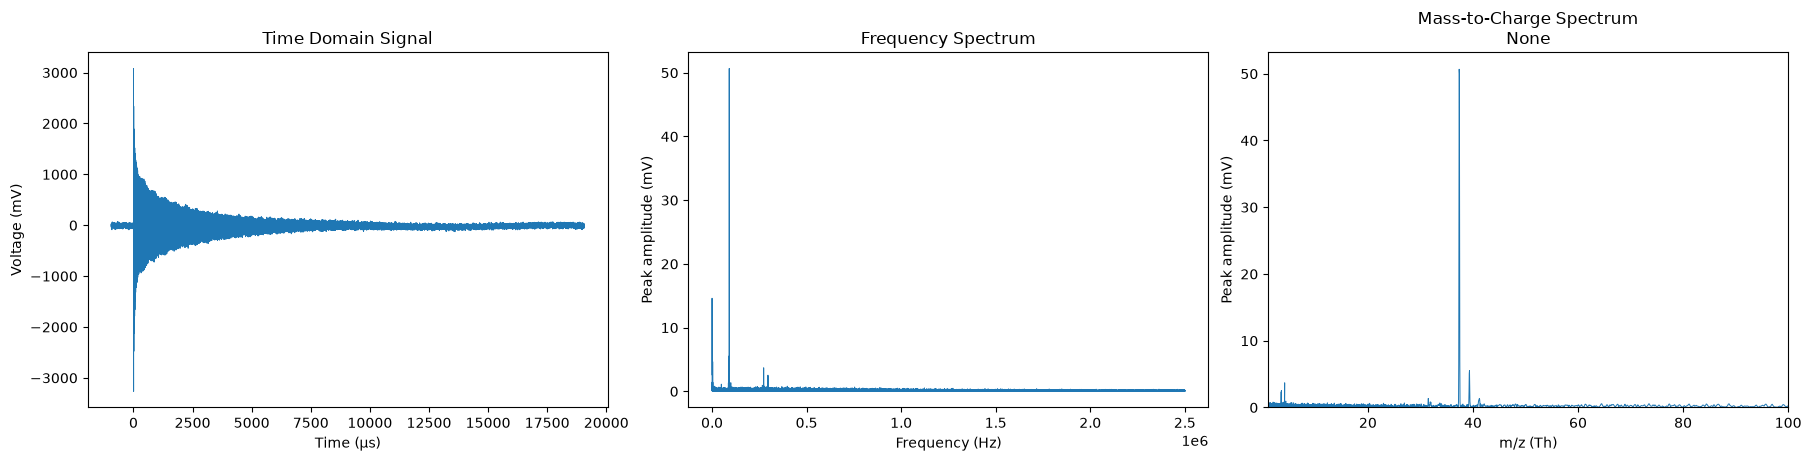

In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.signal.windows import blackmanharris


class DataProcessor:
    """Input units match the original notebook: x in microseconds, y in millivolts."""

    def __init__(self, x, y):
        self.x = np.array(x, dtype=float, copy=True)
        self.y = np.array(y, dtype=float, copy=True)
        
        self.dt_seconds = float((self.x[-1] - self.x[0]) * 1e-6 / (self.x.size - 1))

        self.x.setflags(write=False)
        self.y.setflags(write=False)
        self.dft_freq = self.dft_mag = self.estimated_mz = None
        self.calibration = None

    @classmethod
    def load_data(cls, file_path):
        data = pd.read_csv(file_path, header=None)
        x = pd.to_numeric(data.iloc[:, 3], errors="raise").to_numpy() * 1e6
        y = pd.to_numeric(data.iloc[:, 4], errors="raise").to_numpy() * 1e3
        return cls(x, y)

    def dft(self):
        if self.dft_freq is None:
            n = self.y.size
            window = blackmanharris(n, sym=False)
            # Remove baseline BEFORE windowing to reduce DC leakage.
            spectrum = np.fft.rfft((self.y - self.y.mean()) * window)
            amplitude = np.abs(spectrum) / window.sum()
            # One-sided peak amplitude: do not double DC or the even-N Nyquist bin.
            amplitude[1:-1 if n % 2 == 0 else None] *= 2
            self.dft_freq = np.fft.rfftfreq(n, d=self.dt_seconds)
            self.dft_mag = amplitude  # mV, rather than an unnormalized FFT sum
        return self.dft_freq, self.dft_mag

    def frequency_to_mz(self, *, ref_hz, ref_mz, harmonic_order=1,
                        ref_harmonic_order=1, calibration_label="Unconfirmed reference"):
        """m/z = ref_mz * [(ref_hz / ref_order) / (f / order)]**2.

        ref_hz is an OBSERVED reference frequency in Hz (116 kHz = 116e3).
        Use the reference harmonic separately from the spectrum's harmonic.
        One harmonic order is assumed for this entire mapped spectrum; harmonics
        of a single species can otherwise look like extra species.
        This maps detector amplitude to m/z; it is not abundance or a density.
        """

        frequencies, _ = self.dft()
        positive = frequencies > 0  # DC has no finite m/z; use this mask for amplitudes too.
        self.estimated_mz = ref_mz * (
            (ref_hz / ref_harmonic_order) / (frequencies[positive] / harmonic_order)
        ) ** 2
        self.calibration = str(calibration_label)
        return self.estimated_mz

    def plot(self, *, mz_limits=(1, 100), frequency_limits_hz=None):
        """One plot() interface: time only, time+FFT, or time+FFT+m/z by state.

        mz_limits is a display zoom, not a data filter. Set it to None for all
        masses (the first nonzero FFT bin can map to millions of m/z).
        """
        has_fft = self.dft_freq is not None and self.dft_mag is not None
        has_mz = self.estimated_mz is not None
   
        fig, axes = plt.subplots(1, 1 + int(has_fft) + int(has_mz),
                                 figsize=(6 * (1 + int(has_fft) + int(has_mz)), 4.5),
                                 squeeze=False, layout="constrained")
        axes = axes[0]
        axes[0].plot(self.x, self.y, linewidth=0.7)
        axes[0].set(title="Time Domain Signal", xlabel="Time (µs)", ylabel="Voltage (mV)")
        if has_fft:
            axes[1].plot(self.dft_freq, self.dft_mag, linewidth=0.7)
            axes[1].set(title="Frequency Spectrum", xlabel="Frequency (Hz)",
                        ylabel="Peak amplitude (mV)")
            if frequency_limits_hz is not None:
                axes[1].set_xlim(*frequency_limits_hz)
        if has_mz:
            mz = self.estimated_mz
            magnitude = self.dft_mag[self.dft_freq > 0]
            order = np.argsort(mz)  # inverse-square mapping reverses the frequency order
            ax = axes[-1]
            ax.plot(mz[order], magnitude[order], linewidth=0.7)
            ax.set(title=f"Mass-to-Charge Spectrum\n{self.calibration}",
                   xlabel="m/z (Th)", ylabel="Peak amplitude (mV)")
            if mz_limits is not None:
                ax.set_xlim(*mz_limits)
                visible = (mz >= mz_limits[0]) & (mz <= mz_limits[1])
                if visible.any():
                    ax.set_ylim(0, max(float(magnitude[visible].max()) * 1.05,
                                       np.finfo(float).eps))
        plt.show()
        return fig, axes


# Editable example: these Na settings are from the September slides, not a
# confirmed assignment for k_20ms_avg128_26.5degC.csv. Replace with a measured
# reference at the actual trap settings before interpreting physical masses.
REF_HZ = 116e3
REF_MZ = 23
HARMONIC_ORDER = 1
REF_HARMONIC_ORDER = 1
MZ_LIMITS = (1, 100)  # use None to display every mapped FFT bin

# Works from either the notebooks directory or the project root.
waveform_path = Path(FILE_PATH)
if not waveform_path.is_file():
    waveform_path = Path("data") / waveform_path.name
processor = DataProcessor.load_data(waveform_path)

# Optional: select a settled interval, in µs, before calculating the FFT:
# use = (processor.x >= 0) & (processor.x < 10_000)
# processor = DataProcessor(processor.x[use], processor.y[use])

processor.dft()
processor.frequency_to_mz(
    ref_hz=REF_HZ, ref_mz=REF_MZ, harmonic_order=HARMONIC_ORDER,
    ref_harmonic_order=REF_HARMONIC_ORDER,
    calibration_label=None,
)
fig, axes = processor.plot(mz_limits=MZ_LIMITS)
